In [19]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import accuracy_score, log_loss
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)


Construct a fully connected neural network model for classifying the CIFAR-10 dataset.
Use a 70%-30% split for training and validation data.\
i] Visualize the data by plotting an image from each category from the
CIFAR-10 dataset.\
ii] Demonstrate the tuning of the hyperparameters of the neural network via
grid-search.\
iii] Calculate and plot the training and validation losses of the tuned network.\
iv] Calculate and plot the training and validation accuracies of the tuned
network.

Train: (50000, 3072), Test: (10000, 3072)
Train split: (35000, 3072), Validation split: (15000, 3072)

Running grid search...
Fitting 3 folds for each of 18 candidates, totalling 54 fits

Top configurations from grid search:
  #1: acc=0.4230 (+/- 0.0131)  {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (512, 256), 'mlp__learning_rate_init': 0.0003}
  #2: acc=0.4217 (+/- 0.0062)  {'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes': (512, 256), 'mlp__learning_rate_init': 0.0003}
  #3: acc=0.4205 (+/- 0.0085)  {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (512, 256, 128), 'mlp__learning_rate_init': 0.0003}

Best hyperparameters: {'mlp__alpha': 0.0001, 'mlp__hidden_layer_sizes': (512, 256), 'mlp__learning_rate_init': 0.0003}

Training #1: layers=(512, 256), alpha=0.0001, lr=0.0003
  epoch  1/40  val_loss=1.5555  val_acc=0.4545
  epoch  2/40  val_loss=1.5028  val_acc=0.4776
  epoch  3/40  val_loss=1.4761  val_acc=0.4894
  epoch  4/40  val_loss=1.4632  val_acc=0.4977
  epoch  5/40  val_los

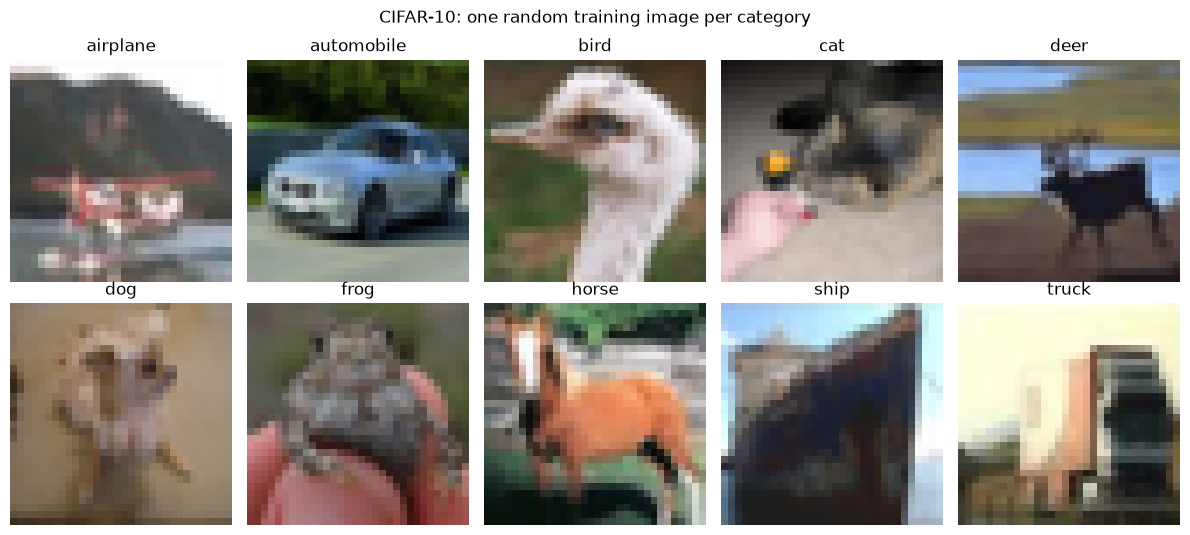

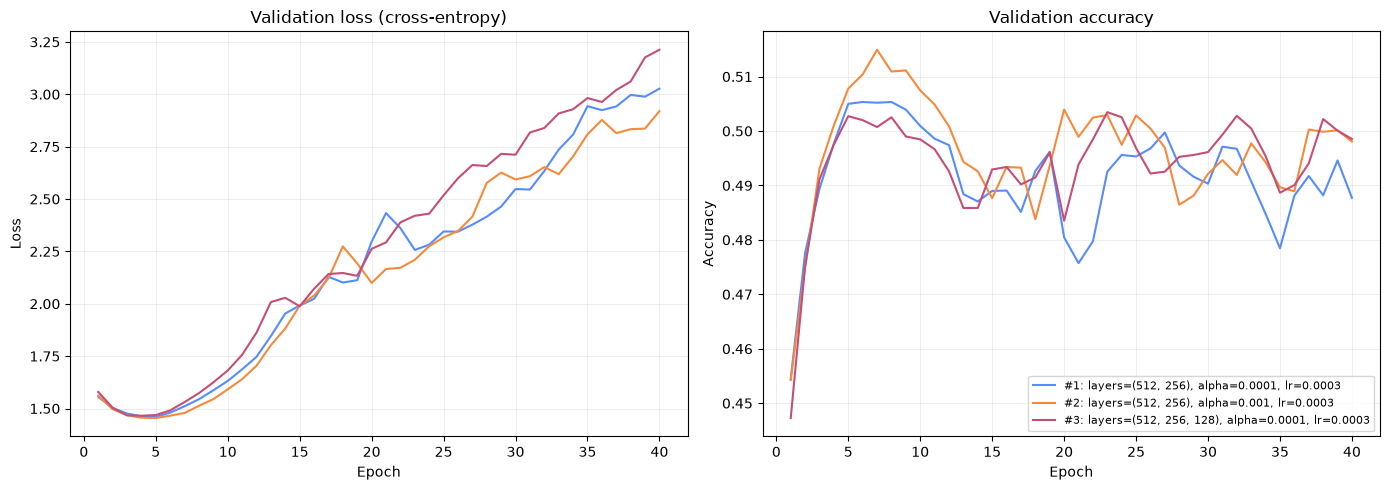

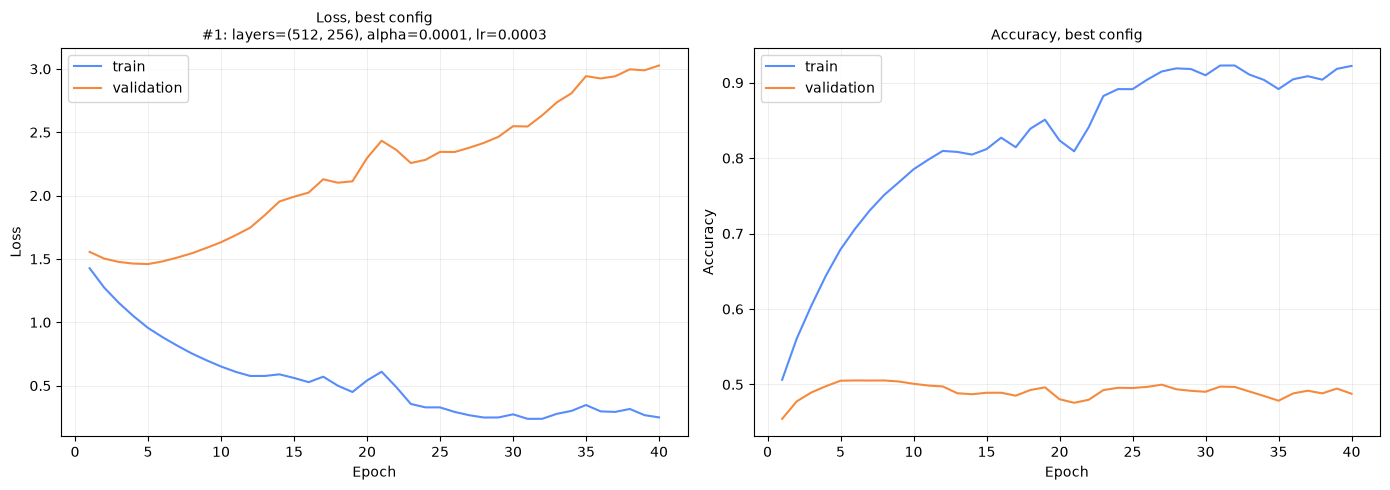

In [14]:
RANDOM_STATE = 123
GRID_SUBSET_SIZE = 10_000   # samples used for grid search (keeps it fast)
FINAL_EPOCHS = 40           # epochs for the per-epoch validation curves
BATCH_SIZE = 256
TOP_K = 3                   # number of best configs to plot curves for


# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
DATA_DIR = "cifar10_data"

def load_cifar10():
    os.makedirs(DATA_DIR, exist_ok=True)
    tar_path = os.path.join(DATA_DIR, "cifar-10-python.tar.gz")
    extract_dir = os.path.join(DATA_DIR, "cifar-10-batches-py")

    def read_batch(name):
        with open(os.path.join(extract_dir, name), "rb") as f:
            batch = pickle.load(f, encoding="bytes")
        return batch[b"data"], np.array(batch[b"labels"])

    train_batches = [read_batch(f"data_batch_{i}") for i in range(1, 6)]
    X_train = np.concatenate([b[0] for b in train_batches]).astype(np.float32) / 255.0
    y_train = np.concatenate([b[1] for b in train_batches]).astype(np.int64)
    X_test, y_test = read_batch("test_batch")
    X_test = X_test.astype(np.float32) / 255.0
    y_test = y_test.astype(np.int64)
    return X_train, y_train, X_test, y_test


X_train_full, y_train_full, X_test, y_test = load_cifar10()
print(f"Train: {X_train_full.shape}, Test: {X_test.shape}")

# Hold out a validation set from the training data
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.3, stratify=y_train_full, random_state=RANDOM_STATE
)
print(f"Train split: {X_train.shape}, Validation split: {X_val.shape}")

# ----------------------------------------------------------------------------
# 2. Hyperparameter tuning with grid search
# ----------------------------------------------------------------------------
pipe = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "mlp",
            MLPClassifier(
                solver="adam",
                batch_size=BATCH_SIZE,
                max_iter=30,
                early_stopping=True,
                n_iter_no_change=5,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

param_grid = {
    "mlp__hidden_layer_sizes": [(256,), (512, 256), (512, 256, 128)],
    "mlp__alpha": [1e-4, 1e-3, 1e-2],            # L2 regularization
    "mlp__learning_rate_init": [1e-3, 3e-4],
}

rng = np.random.RandomState(RANDOM_STATE)
subset_idx = rng.choice(len(X_train), size=GRID_SUBSET_SIZE, replace=False)

grid = GridSearchCV(
    pipe,
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=2,
    refit=False,
    return_train_score=False,
)
print("\nRunning grid search...")
grid.fit(X_train[subset_idx], y_train[subset_idx])

results = grid.cv_results_
order = np.argsort(results["rank_test_score"])
print("\nTop configurations from grid search:")
for rank, i in enumerate(order[:TOP_K], start=1):
    print(f"  #{rank}: acc={results['mean_test_score'][i]:.4f} "
          f"(+/- {results['std_test_score'][i]:.4f})  {results['params'][i]}")

best_params = results["params"][order[0]]
print("\nBest hyperparameters:", best_params)

# ----------------------------------------------------------------------------
# 3. Re-train top configs epoch by epoch to record validation loss / accuracy
# ----------------------------------------------------------------------------
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)
classes = np.arange(10)


def train_with_curves(params, epochs=FINAL_EPOCHS):
    """Train an MLP with partial_fit, recording train/val loss and accuracy each epoch."""
    mlp_params = {k.replace("mlp__", ""): v for k, v in params.items()}
    model = MLPClassifier(
        solver="adam",
        batch_size=BATCH_SIZE,
        random_state=RANDOM_STATE,
        **mlp_params,
    )
    history = {"val_loss": [], "val_acc": [], "train_loss": [], "train_acc": []}
    for epoch in range(epochs):
        model.partial_fit(X_train_s, y_train, classes=classes)  # one pass over the data
        val_proba = model.predict_proba(X_val_s)
        train_proba = model.predict_proba(X_train_s)
        history["val_loss"].append(log_loss(y_val, val_proba, labels=classes))
        history["val_acc"].append(accuracy_score(y_val, val_proba.argmax(axis=1)))
        history["train_loss"].append(log_loss(y_train, train_proba, labels=classes))
        history["train_acc"].append(accuracy_score(y_train, train_proba.argmax(axis=1)))
        print(f"  epoch {epoch + 1:2d}/{epochs}  "
              f"val_loss={history['val_loss'][-1]:.4f}  val_acc={history['val_acc'][-1]:.4f}")
    return model, history


histories = {}
models = {}
for rank, i in enumerate(order[:TOP_K], start=1):
    params = results["params"][i]
    label = (f"#{rank}: layers={params['mlp__hidden_layer_sizes']}, "
             f"alpha={params['mlp__alpha']}, lr={params['mlp__learning_rate_init']}")
    print(f"\nTraining {label}")
    models[label], histories[label] = train_with_curves(params)

# ----------------------------------------------------------------------------
# 4. One random example image from each CIFAR-10 category
# ----------------------------------------------------------------------------
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

sample_rng = np.random.RandomState()  # unseeded: a different random image each run
fig_img, axes_img = plt.subplots(2, 5, figsize=(12, 5.5))
for class_id, ax in enumerate(axes_img.ravel()):
    idx = sample_rng.choice(np.flatnonzero(y_train_full == class_id))
    # Each row is stored as 1024 red, then 1024 green, then 1024 blue values
    image = X_train_full[idx].reshape(3, 32, 32).transpose(1, 2, 0)
    ax.imshow(image)
    ax.set_title(CLASS_NAMES[class_id])
    ax.axis("off")
fig_img.suptitle("CIFAR-10: one random training image per category")
plt.tight_layout()
plt.savefig("cifar10_sample_images.png", dpi=150)
print("Saved plot to cifar10_sample_images.png")

# ----------------------------------------------------------------------------
# 5. Plot validation loss and validation accuracy
# ----------------------------------------------------------------------------
epochs_axis = np.arange(1, FINAL_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, h in histories.items():
    axes[0].plot(epochs_axis, h["val_loss"], label=label)
    axes[1].plot(epochs_axis, h["val_acc"], label=label)

axes[0].set_title("Validation loss (cross-entropy)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8, loc="lower right")

plt.tight_layout()
plt.savefig("cifar10_validation_curves.png", dpi=150)
print("\nSaved plot to cifar10_validation_curves.png")

# Best config: train vs. validation curves (useful for spotting overfitting)
best_label = next(iter(histories))
h = histories[best_label]
fig2, ax2 = plt.subplots(1, 2, figsize=(14, 5))
ax2[0].plot(epochs_axis, h["train_loss"], label="train")
ax2[0].plot(epochs_axis, h["val_loss"], label="validation")
ax2[0].set_title(f"Loss, best config\n{best_label}", fontsize=10)
ax2[0].set_xlabel("Epoch"); ax2[0].set_ylabel("Loss"); ax2[0].legend(); ax2[0].grid(alpha=0.3)
ax2[1].plot(epochs_axis, h["train_acc"], label="train")
ax2[1].plot(epochs_axis, h["val_acc"], label="validation")
ax2[1].set_title("Accuracy, best config", fontsize=10)
ax2[1].set_xlabel("Epoch"); ax2[1].set_ylabel("Accuracy"); ax2[1].legend(); ax2[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig("cifar10_best_config_train_vs_val.png", dpi=150)
print("Saved plot to cifar10_best_config_train_vs_val.png")

# ----------------------------------------------------------------------------
# 6. Final test-set evaluation of the best model
# ----------------------------------------------------------------------------
best_model = models[best_label]
test_pred = best_model.predict(X_test_s)
print(f"\nTest accuracy of best model: {accuracy_score(y_test, test_pred):.4f}")

plt.show()

Obtain the NASA airfoil self-noise dataset from UCI machine learning dataset repository.
The dataset describes different size NACA 0012 airfoils at various wind tunnel speeds
and angles of attack. The span of the airfoil and the observer position were the same in
all of the experiments. The following attributes were measured:\
i. Frequency, in Hz.\
ii. Angle of attack, in degrees.\
iii. Chord length, in meters.\
iv. Free-stream velocity, in meters per second.\
v. Suction side displacement thickness, in meters.\
The only measured output was:\
i. Scaled sound pressure level, in decibels.\
i] Visualize the dataset.\
ii] Construct a fully connected neural network model for estimating scaled
sound pressure level, in decibels, from the attributes by choosing a 70%-30% split.\
iii] Calculate the coefficient of determination

Dataset: 1503 samples, 5 features
Train: 1052 samples, Test: 451 samples

Training the neural network...
Stopped after 600 epochs (final training loss: 0.00817)

Results
------------------------------------------------------------
Train:  R^2 = 0.9841   RMSE = 0.858 dB   MAE = 0.614 dB
 Test:  R^2 = 0.9486   RMSE = 1.612 dB   MAE = 1.130 dB
Saved plot to airfoil_dataset_pairplot.png

Saved plot to airfoil_mlp_results.png


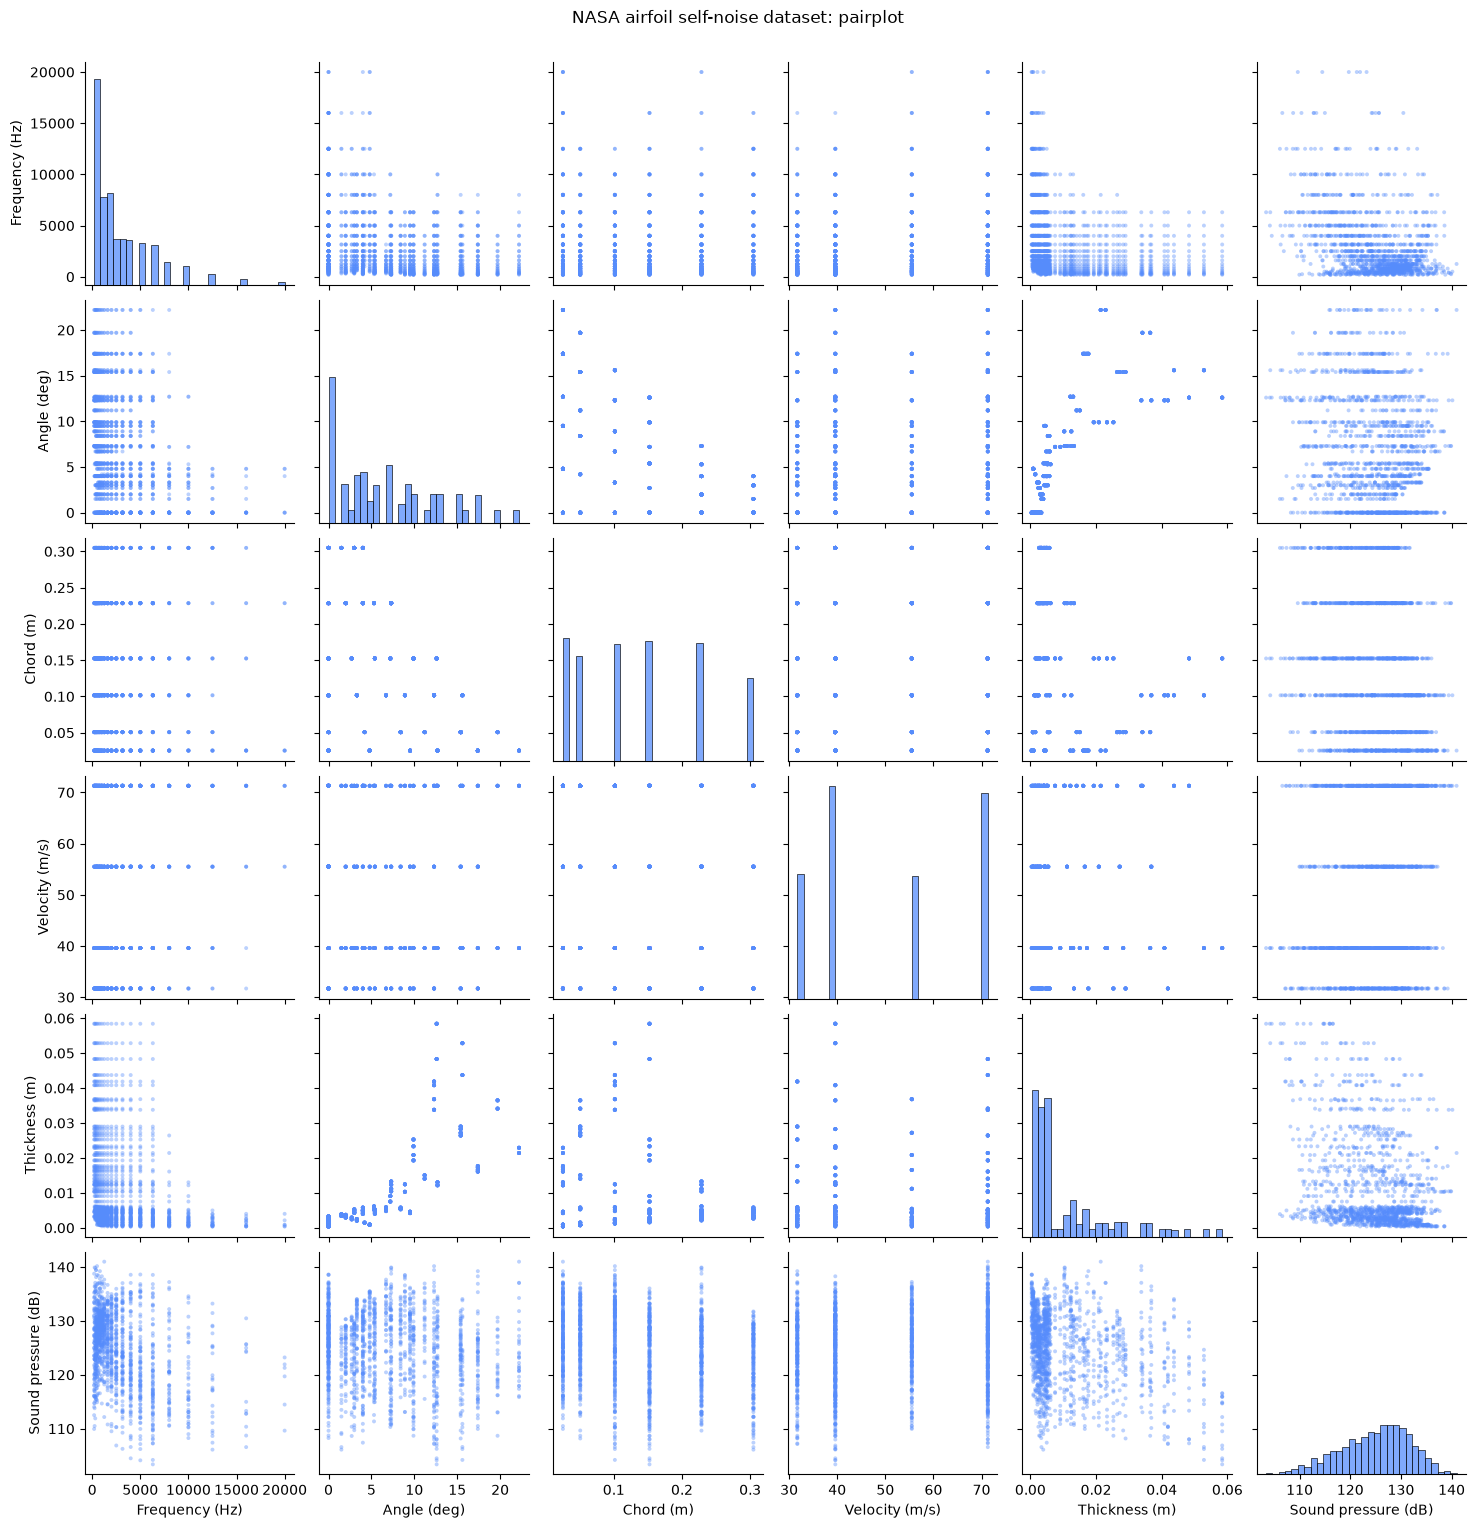

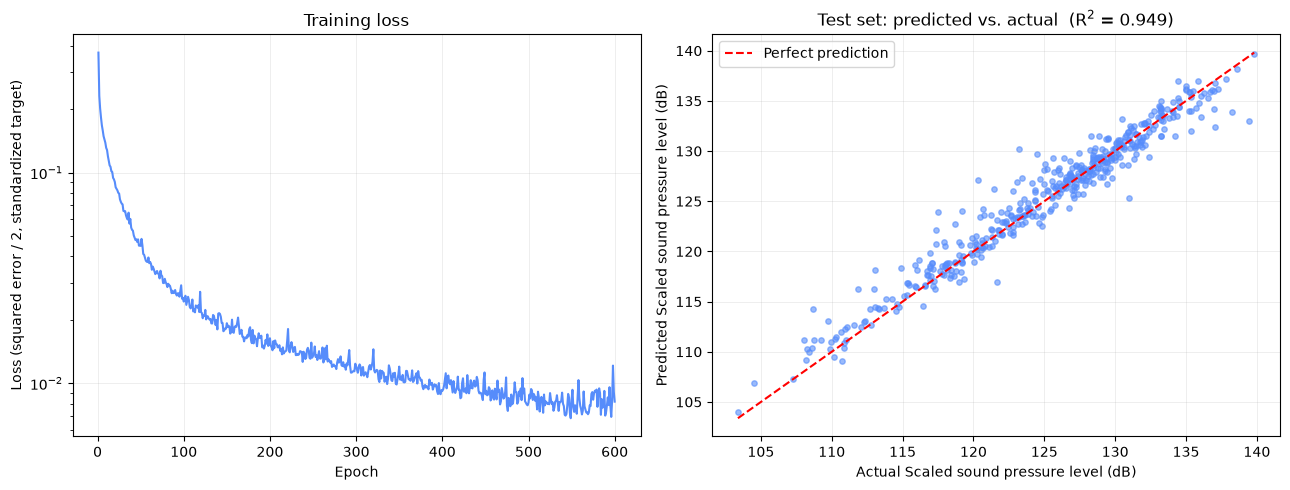

In [18]:
RANDOM_STATE = 123
DATA_DIR = "airfoil_data"
DATA_FILE = os.path.join(DATA_DIR, "airfoil_self_noise.dat")

FEATURE_NAMES = [
    "Frequency (Hz)",
    "Angle of attack (deg)",
    "Chord length (m)",
    "Free-stream velocity (m/s)",
    "Suction side displacement thickness (m)",
]
TARGET_NAME = "Scaled sound pressure level (dB)"


# ----------------------------------------------------------------------------
# 1. Data
# ----------------------------------------------------------------------------
def download_dataset():
    """Download the dataset from UCI into ./airfoil_data (only if not already there)."""
    os.makedirs(DATA_DIR, exist_ok=True)
    if os.path.exists(DATA_FILE):
        return


def load_airfoil():
    """Return X (n, 5) and y (n,). The .dat file is tab-separated with no header row."""
    download_dataset()
    data = np.loadtxt(DATA_FILE)  # whitespace/tab separated
    assert data.shape[1] == 6, f"Unexpected number of columns: {data.shape}"
    return data[:, :5], data[:, 5]


X, y = load_airfoil()
print(f"Dataset: {X.shape[0]} samples, {X.shape[1]} features")

# 70% training / 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE
)
print(f"Train: {X_train.shape[0]} samples, Test: {X_test.shape[0]} samples")

# ----------------------------------------------------------------------------
# 2. Model: fully connected neural network
# ----------------------------------------------------------------------------
# Inputs are standardized by the pipeline; the target is standardized by
# TransformedTargetRegressor (predictions are automatically converted back to dB).
mlp = MLPRegressor(
    hidden_layer_sizes=(64, 64),
    activation="relu",
    solver="adam",
    alpha=1e-4,                # L2 regularization
    learning_rate_init=1e-3,
    batch_size=32,
    max_iter=2000,
    tol=1e-6,
    n_iter_no_change=50,
    random_state=RANDOM_STATE,
)

model = TransformedTargetRegressor(
    regressor=Pipeline([("scaler", StandardScaler()), ("mlp", mlp)]),
    transformer=StandardScaler(),
)

print("\nTraining the neural network...")
model.fit(X_train, y_train)
fitted_mlp = model.regressor_.named_steps["mlp"]
print(f"Stopped after {fitted_mlp.n_iter_} epochs (final training loss: {fitted_mlp.loss_:.5f})")

# ----------------------------------------------------------------------------
# 3. Evaluation (including the coefficient of determination, R^2)
# ----------------------------------------------------------------------------
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


def report(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:>5s}:  R^2 = {r2:.4f}   RMSE = {rmse:.3f} dB   MAE = {mae:.3f} dB")
    return r2


print("\nResults")
print("-" * 60)
r2_train = report("Train", y_train, y_train_pred)
r2_test = report("Test", y_test, y_test_pred)

# ----------------------------------------------------------------------------
# 4. Pairplot of the dataset
# ----------------------------------------------------------------------------
# Short column names keep the 6x6 grid of axis labels readable
PAIRPLOT_COLUMNS = [
    "Frequency (Hz)",
    "Angle (deg)",
    "Chord (m)",
    "Velocity (m/s)",
    "Thickness (m)",
    "Sound pressure (dB)",
]
df = pd.DataFrame(np.column_stack([X, y]), columns=PAIRPLOT_COLUMNS)

pair_grid = sns.pairplot(
    df,
    diag_kind="hist",
    plot_kws={"s": 8, "alpha": 0.4, "edgecolor": "none"},
    diag_kws={"bins": 30},
)
pair_grid.figure.suptitle("NASA airfoil self-noise dataset: pairplot", y=1.02)
pair_grid.savefig("airfoil_dataset_pairplot.png", dpi=150)
print("Saved plot to airfoil_dataset_pairplot.png")

# ----------------------------------------------------------------------------
# 5. Plots
# ----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training loss curve (loss is on the standardized target scale)
axes[0].plot(np.arange(1, len(fitted_mlp.loss_curve_) + 1), fitted_mlp.loss_curve_)
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss (squared error / 2, standardized target)")
axes[0].set_yscale("log")
axes[0].grid(alpha=0.3)

# Predicted vs. actual on the test set
axes[1].scatter(y_test, y_test_pred, s=15, alpha=0.6)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
axes[1].plot(lims, lims, "r--", label="Perfect prediction")
axes[1].set_title(f"Test set: predicted vs. actual  (R$^2$ = {r2_test:.3f})")
axes[1].set_xlabel(f"Actual {TARGET_NAME}")
axes[1].set_ylabel(f"Predicted {TARGET_NAME}")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("airfoil_mlp_results.png", dpi=150)
print("\nSaved plot to airfoil_mlp_results.png")

plt.show()